# Cat & Dog Classification
## STEP 1: Import Important Libraries

In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import img_to_array, load_img
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## STEP 2: Load and Preprocess the Data

In [10]:
possible_paths = [
    './dataset',
    '../dataset',
    os.path.join(os.getcwd(), 'dataset')
]

data_dir = None
for path in possible_paths:
    if os.path.exists(path):
        data_dir = path
        break

if data_dir:
    print(f"✅ Dataset found at: {os.path.abspath(data_dir)}")
else:
    print("❌ Dataset not found! Make sure your 'dataset' folder contains 'cats' and 'dogs' subfolders.")

✅ Dataset found at: d:\MTEC\Image-Processing\Cat and Dog Classification\dataset


### Clean the Dataset (Remove non-image file)
If you have already run this, please comment it out.

In [11]:
# bad_images_count = 0
# valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# print("Cleaning dataset thoroughly (removing non-images and corrupted files)...")

# for root, dirs, files in os.walk(data_dir):
#     for file in files:
#         file_path = os.path.join(root, file)
        
#         # 1. Remove hidden or non-image files (like Thumbs.db, .txt, etc.)
#         if not file.lower().endswith(valid_extensions):
#             try:
#                 os.remove(file_path)
#                 print(f"🗑️ Removed non-image file: {file_path}")
#                 bad_images_count += 1
#             except Exception as e:
#                 pass
#             continue
            
#         # 2. Verify image integrity
#         try:
#             with Image.open(file_path) as img:
#                 img.verify()
#         except Exception as e:
#             bad_images_count += 1
#             print(f"❌ Removed corrupted image: {file_path}")
#             try:
#                 os.remove(file_path)
#             except:
#                 pass

# print(f"\nCleanup complete! Removed {bad_images_count} invalid file(s).")

## STEP 3: Train-Validation-Test Split
Note: Because our dataset is large and can cause Jupyter memory crashes, we select only a subset of the data. You can adjust the number of images where you see the comment `` # Adjust lower (e.g., 300) if you hit memory issues ``. The number will be for all Cats and Dogs: 1000 = 1000 for Cat images and 1000 for Dog images.

In [12]:
BATCH_SIZE = 32
IMG_SIZE = (160, 160)
MAX_IMAGES_PER_CLASS = 1000  # Adjust lower (e.g., 300) if you hit memory issues

print(f"Loading up to {MAX_IMAGES_PER_CLASS} images per class...")

images = []
labels = []
class_names = sorted(os.listdir(data_dir))
class_names = [c for c in class_names if os.path.isdir(os.path.join(data_dir, c))]

for idx, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    files = os.listdir(class_path)
    
    np.random.seed(123)
    np.random.shuffle(files)
    
    count = 0
    for file in files:
        if count >= MAX_IMAGES_PER_CLASS:
            break
            
        file_path = os.path.join(class_path, file)
        try:
            with Image.open(file_path) as img:
                img = img.convert('RGB')
                img = img.resize(IMG_SIZE)
                arr = img_to_array(img)
                images.append(arr)
                labels.append(idx)
                count += 1
        except:
            pass

images = np.array(images, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)

print(f"✅ Total images loaded: {len(images)} | Classes: {class_names}")

# Shuffle indices
indices = np.arange(len(images))
np.random.seed(123)
np.random.shuffle(indices)

images = images[indices]
labels = labels[indices]

# Split Ratios: 70% Train, 15% Validation, 15% Test
train_split = int(0.70 * len(images))
val_split = int(0.85 * len(images))

train_images, val_images, test_images = images[:train_split], images[train_split:val_split], images[val_split:]
train_labels, val_labels, test_labels = labels[:train_split], labels[train_split:val_split], labels[val_split:]

print(f"Dataset Splits -> Train: {len(train_images)} | Val: {len(val_images)} | Test: {len(test_images)}")

# Create tf.data.Dataset objects
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels)).shuffle(1000).batch(BATCH_SIZE)
validation_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_labels)).batch(BATCH_SIZE)

Loading up to 1000 images per class...
✅ Total images loaded: 2000 | Classes: ['Cat', 'Dog']
Dataset Splits -> Train: 1400 | Val: 300 | Test: 300


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

## STEP 4: Build the Model (Transfer Learning)

In [14]:
# Use pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)

# Freeze base model weights
base_model.trainable = False

# Construct classifier head
model = models.Sequential([
    layers.Rescaling(1./127.5, offset=-1, input_shape=IMG_SIZE + (3,)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid') # Binary classification (Cat vs Dog)
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

d:\MTEC\Image-Processing\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## STEP 5: Train the Model

In [15]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10


d:\MTEC\Image-Processing\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


44/44 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.9050 - loss: 0.2529 - val_accuracy: 0.9867 - val_loss: 0.0815
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.9736 - loss: 0.0926 - val_accuracy: 0.9967 - val_loss: 0.0550
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 829ms/step - accuracy: 0.9836 - loss: 0.0617 - val_accuracy: 0.9967 - val_loss: 0.0384
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 35s 798ms/step - accuracy: 0.9871 - loss: 0.0518 - val_accuracy: 0.9967 - val_loss: 0.0317
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 886ms/step - accuracy: 0.9886 - loss: 0.0378 - val_accuracy: 0.9967 - val_loss: 0.0321
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9886 - loss: 0.0344 - val_accuracy: 1.0000 - val_loss: 0.0253
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.9943 - loss: 0.0295 - val_accuracy: 1.0000 - val_loss: 0.0248
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.9943 - loss: 0.0294 - val_accuracy: 1.0000 - val_loss: 

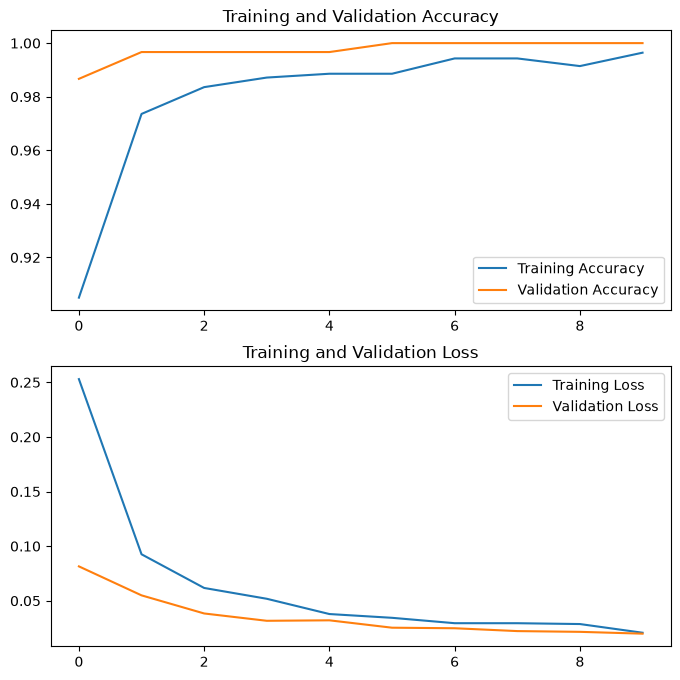

In [16]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## STEP 6: Save the Model

In [17]:
model.save('cat_dog_classifier.keras')
print("Model saved successfully as 'cat_dog_classifier.keras'!")

Model saved successfully as 'cat_dog_classifier.keras'!


## STEP 7: Test Set Evaluation & Visualisation

10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9667 - loss: 0.0791

🎯 Final Test Set Accuracy: 96.67%


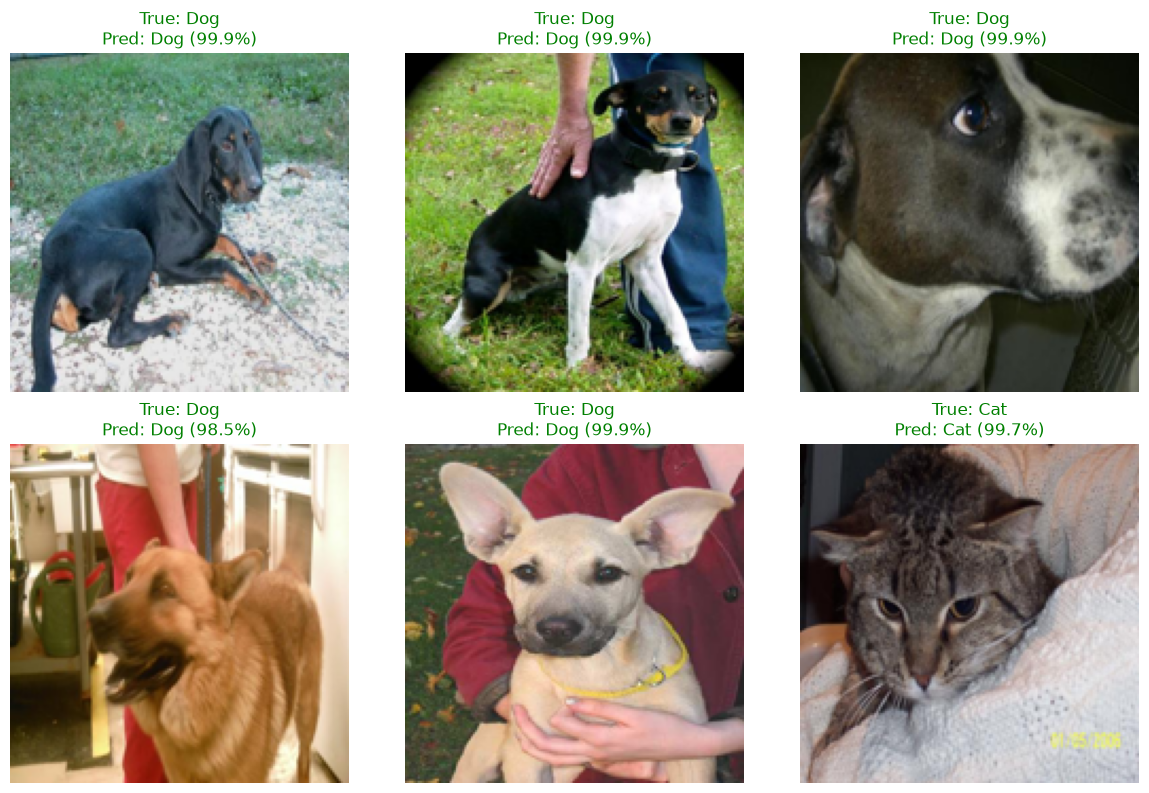

In [18]:
# 1. Evaluate accuracy on the unused test set
test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels)).batch(BATCH_SIZE)
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\n🎯 Final Test Set Accuracy: {test_acc * 100:.2f}%")

# 2. Visualize predictions on random test images
num_images_to_show = 6
plt.figure(figsize=(12, 8))

random_indices = np.random.choice(len(test_images), min(num_images_to_show, len(test_images)), replace=False)

for i, idx in enumerate(random_indices):
    img_array = test_images[idx]
    true_label_idx = test_labels[idx]
    true_label_name = class_names[true_label_idx]
    
    # Predict
    prediction_input = tf.expand_dims(img_array, 0)
    score = model.predict(prediction_input, verbose=0)[0][0]
    
    if score > 0.5:
        pred_label_name = class_names[1] # Dog
        confidence = score * 100
    else:
        pred_label_name = class_names[0] # Cat
        confidence = (1 - score) * 100
        
    # Plot
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_array.astype('uint8'))
    plt.axis('off')
    
    color = 'green' if pred_label_name == true_label_name else 'red'
    plt.title(f"True: {true_label_name}\nPred: {pred_label_name} ({confidence:.1f}%)", color=color)

plt.tight_layout()
plt.show()

In [19]:
import tf2onnx
import onnx

# Define the file path for the ONNX model
onnx_path = r'D:\MTEC\Image-Processing\Cat and Dog Classification\cat_dog_classifier.onnx'

# Specify the input signature (Batch size can be None for dynamic batching, matching your input shape)
input_signature = [tf.TensorSpec((None, IMG_SIZE[0], IMG_SIZE[1], 3), tf.float32, name='image_input')]

# Convert the Keras model to ONNX format
model_proto, _ = tf2onnx.convert.from_keras(model, input_signature=input_signature, opset=13)

# Save the ONNX model to disk
onnx.save(model_proto, onnx_path)
print(f"Model saved successfully as '{onnx_path}'!")

KeyError: 'keras_tensor_1814'